# Week 6 — Ethical and Legal Considerations in AI: fairness audit of a credit model

A consumer lender asks us to check its new credit-scoring model **before launch**. The model never sees the applicant's gender. Our job is to find out whether it still treats women and men differently, **what it would cost to close the gap**, and what the law says about the options.

**NOTE**: These are really complicated matters and it takes a lot of time, I am just trying to give you a glimpse of some of the problems you will face in this field. You can finish entire PhD on AI fairness, and the field is becoming even more important with new regulation and guardrails being introduced by different countries and governments

| Part | Topic |
|---|---|
| A | The data: a pilot loan book |
| B | The model and the week-3 threshold |
| C | Fairness audit: approval rate, TPR, FPR, precision by group |
| D | The proxy test |
| E | Moving the threshold: what fairness costs |
| F | Remove the strongest proxy (and the fix the law forbids) |
| G | Classify ten use cases by AI Act risk tier |
| H | Memo to the credit committee |

Everything comes from the week-3 confusion matrix, computed **separately for each group**.

In [1]:
# Import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [2]:
# Set some parameters
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (8, 4),
                     "axes.spines.top": False,
                     "axes.spines.right": False,
                     "axes.grid": True,
                     "grid.alpha": 0.3})
BLUE, ORANGE, GREY, RED = "#2a78d6", "#eb6834", "#7a7a7a", "#c4553d"

# Part A — The data

**NociBank** (an invented consumer lender in Tirana) gives small personal loans of €500–10,000.

Normally a lender only learns whether a loan is repaid if it **approved** the loan: thus, the rejected applicants are missing from the data (*selection bias*).

To get around this, in 2025 NociBank ran a **pilot** project: for six months it approved **every** applicant and recorded who repaid. Recall the beginning when we talked about the history of credit scoring and how **Signet Bank** used an experimental approach to get real data with its "exploration budget". It costs money, but it gives us outcomes for everyone without bias.

| column | meaning |
|---|---|
| `gender` | F or M. Kept by the compliance team for audits only; **not** used by the model |
| `age` | years |
| `region` | Tirana, Other city, Rural |
| `employment` | public, private, self-employed |
| `part_time` | 1 if the applicant works part time |
| `career_gap_months` | months without work in the last 10 years (e.g. parental leave, illness, unemployment) |
| `monthly_income` | net monthly income (€) |
| `credit_history_months` | length of credit history at the credit bureau |
| `debt_to_income` | existing monthly debt payments ÷ income |
| `late_payments_12m` | late payments in the last 12 months |
| `loan_amount` | € requested |
| `default` | 1 if the loan was not repaid within 12 months |

### Simulating the pilot loan book

The real data would come from NociBank's systems. Here we **simulate** it, with a fixed random seed so everyone gets the same numbers.
You don't need to read this cell, only run it. However, id higly recommend you test these functions to learn about simulations. You'll thanke me later!

In [3]:
# Simulated data
def make_data(seed=6, n=6000):
    rng = np.random.default_rng(seed)
    female = rng.random(n) < 0.45
    age = np.clip(np.round(rng.normal(37, 10, n)), 21, 65).astype(int)
    u = rng.random(n)
    emp = np.where(female,
                   np.select([u < 0.36, u < 0.86], ["public", "private"], "self-employed"),
                   np.select([u < 0.24, u < 0.72], ["public", "private"], "self-employed"))
    part_time = (rng.random(n) < np.where(female, 0.30, 0.07)).astype(int)
    has_gap = rng.random(n) < np.where(female, 0.48, 0.12)
    gap = np.where(has_gap, np.round(rng.exponential(np.where(female, 16, 9), n)) + 3, 0).clip(0, 96).astype(int)
    region = rng.choice(["Tirana", "Other city", "Rural"], n, p=[0.5, 0.32, 0.18])
    inc = 720 * np.exp(rng.normal(0, 0.35, n))
    inc *= np.where(female, 0.78, 1.0) * np.where(part_time == 1, 0.62, 1.0)
    inc *= np.select([emp == "public", emp == "self-employed"], [1.03, 1.08], 1.0)
    inc *= np.where(region == "Tirana", 1.12, np.where(region == "Rural", 0.82, 1.0))
    inc *= 1 + 0.012 * np.clip(age - 25, 0, 25)
    income = np.round(inc, -1)
    history = np.clip(np.round((age - 20) * 12 * rng.uniform(0.25, 0.9, n) - 1.0 * gap), 0, None).astype(int)
    dti = np.clip(rng.beta(2.2, 5.5, n), 0.02, 0.85).round(2)
    late = rng.poisson(np.where(rng.random(n) < 0.25, 1.4, 0.15)).clip(0, 6)
    loan = (np.round(rng.lognormal(np.log(2800), 0.5, n), -2)).clip(500, 10000).astype(int)

    logit = (-1.75 - 1.05 * np.log(income / 720) + 3.0 * (dti - 0.29) + 0.50 * late
             - 0.006 * (history - 120) + 0.40 * (emp == "self-employed") - 0.20 * (emp == "public")
             + 0.20 * (region == "Rural") + 0.18 * np.log(loan / 2800) + 0.002 * gap
             - 0.32 * female)
    p = 1 / (1 + np.exp(-logit))
    default = (rng.random(n) < p).astype(int)
    df = pd.DataFrame({"applicant_id": np.arange(100001, 100001 + n),
                       "gender": np.where(female, "F", "M"), "age": age, "region": region,
                       "employment": emp, "part_time": part_time, "career_gap_months": gap,
                       "monthly_income": income.astype(int), "credit_history_months": history,
                       "debt_to_income": dti, "late_payments_12m": late, "loan_amount": loan,
                       "default": default})
    return df

loans = make_data()
print(loans.shape)

(6000, 13)


In [4]:
loans.head()

,applicant_id,gender,age,region,employment,part_time,career_gap_months,monthly_income,credit_history_months,debt_to_income,late_payments_12m,loan_amount,default
0,100001,M,48,Other city,private,0,0,860,245,0.61,0,3200,0
1,100002,F,50,Tirana,public,1,0,790,90,0.39,1,1900,0
2,100003,F,42,Tirana,public,0,13,650,59,0.02,0,3000,0
3,100004,F,48,Other city,public,1,0,290,292,0.21,0,1800,0
4,100005,M,37,Tirana,private,0,0,620,95,0.53,0,6400,0


## A1. Women and men in the pilot

In [5]:
profile = loans.groupby("gender").agg(
    applicants=("default", "size"),
    default_rate=("default", "mean"),
    median_income=("monthly_income", "median"),
    part_time=("part_time", "mean"),
    has_career_gap=("career_gap_months", lambda s: (s > 0).mean()),
    credit_history=("credit_history_months", "mean"),
    debt_to_income=("debt_to_income", "mean"),
    late_payments=("late_payments_12m", "mean"),
).round(3)

profile

,applicants,default_rate,median_income,part_time,has_career_gap,credit_history,debt_to_income,late_payments
gender,,,,,,,,
F,2681,0.217,580.0,0.292,0.483,107.258,0.288,0.442
M,3319,0.205,840.0,0.065,0.115,118.730,0.293,0.469


### A set of questions to discuss

1. Do women and men in the pilot default at different rates?

2. On which features do women and men differ most? Which of these differences come from the labour market rather than from how people handle credit?

3. Prediction: the model will not see gender. Will it approve the same share of women and men?

In [6]:
# Transpose the table to make it easier to see
profile.T

gender,F,M
applicants,2681.000,3319.000
default_rate,0.217,0.205
median_income,580.000,840.000
part_time,0.292,0.065
has_career_gap,0.483,0.115
credit_history,107.258,118.730
debt_to_income,0.288,0.293
late_payments,0.442,0.469


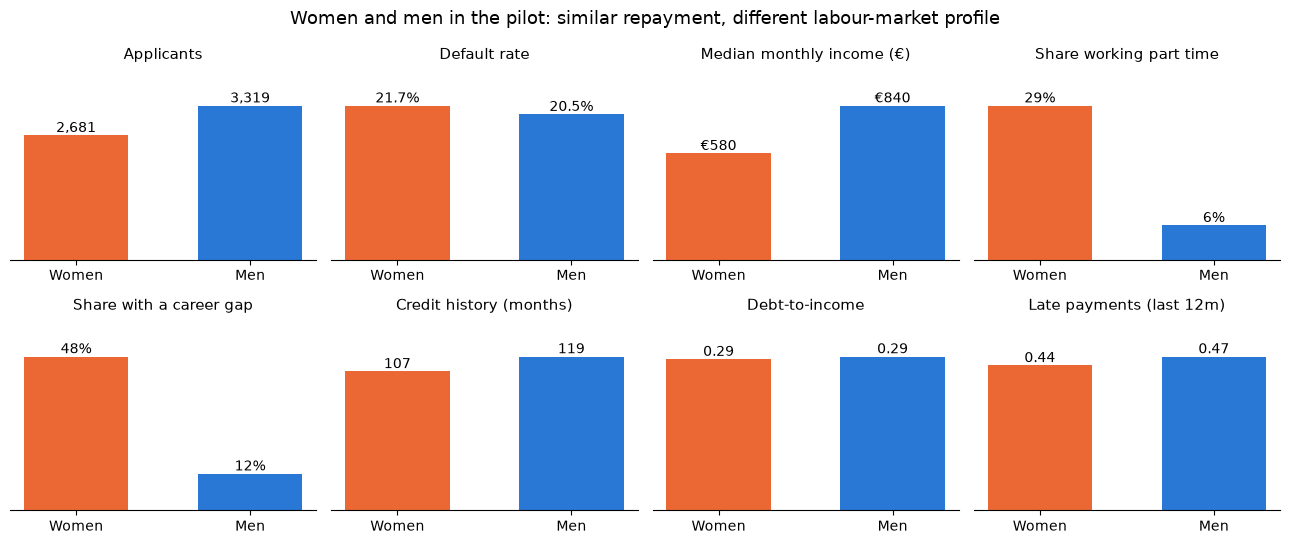

In [8]:
# Create a list of tuples (or dictionaries): # column, title, how to print the value
PANELS = [
    ("applicants", "Applicants", "{:,.0f}"),
    ("default_rate", "Default rate", "{:.1%}"),
    ("median_income", "Median monthly income (€)", "€{:,.0f}"),
    ("part_time", "Share working part time", "{:.0%}"),
    ("has_career_gap", "Share with a career gap", "{:.0%}"),
    ("credit_history", "Credit history (months)", "{:.0f}"),
    ("debt_to_income", "Debt-to-income", "{:.2f}"),
    ("late_payments", "Late payments (last 12m)", "{:.2f}"),
]

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, (col, title, fmt) in zip(axes.flat, PANELS):
    vals = profile[col]
    bars = ax.bar(["Women", "Men"], vals, color=[ORANGE, BLUE], width=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v), ha="center", va="bottom", fontsize=10)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.set_yticks([])
    ax.grid(False)
    ax.spines["left"].set_visible(False)
fig.suptitle("Women and men in the pilot: similar repayment, different labour-market profile", fontsize=13)
plt.tight_layout()
plt.show()

# Part B — The model and the week-3 threshold

Same steps as week 3: split into a **training** set (60%) and a **test** set (40%), fit a logistic regression, and judge it on the test set only.
The model gets every column **except** `gender`, `applicant_id` and of course `default`.

In [9]:
NUMERIC = ["age", "part_time", "career_gap_months", "credit_history_months",
           "debt_to_income", "late_payments_12m"]

def features(df, drop=(), add_gender=False):
    # The model's inputs. Income and loan amount are used as logs (a 10% change matters the
    # same at €500 as at €1,500). Region and employment become 0/1 columns.
    X = df[NUMERIC].copy()
    X["log_income"] = np.log(df["monthly_income"])
    X["log_loan"] = np.log(df["loan_amount"])
    X = pd.concat([X, pd.get_dummies(df[["region", "employment"]], drop_first=True, dtype=int)], axis=1)
    if add_gender:
        X["female"] = (df["gender"] == "F").astype(int)
    return X.drop(columns=list(drop))

train, test = train_test_split(loans, test_size=0.4, random_state=6, stratify=loans["default"])
test = test.copy()

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(features(train), train["default"])
test["p_default"] = model.predict_proba(features(test))[:, 1]

print(f"Training rows: {len(train):,}   Test rows: {len(test):,}")
print(f"Test AUC: {roc_auc_score(test['default'], test['p_default']):.3f}")

Training rows: 3,600   Test rows: 2,400
Test AUC: 0.749


## B2. From probability to decision: the break-even threshold

Assume that a repaid loan earns **+€300** (interest and fees), a default loses **−€1,000** on average.

Approve when the expected value is positive (Remember the examples with Lali and Fiku with expected value):

`300 × (1 − p) − 1,000 × p > 0`  →  `p < 300 / 1,300 ≈ 23.1%`

Also, let's clarify the following statement because everything depends on this:

In credit, **approval is the "positive" decision**. So a *true positive* is an approved applicant who repays, and a *false positive* is an approved applicant who defaults.

In [10]:
GAIN, LOSS = 300, 1000
BREAK_EVEN = GAIN / (GAIN + LOSS)

def profit(df, approved):
    # € profit of a set of approval decisions on applicants whose outcome we know
    good = df["default"] == 0
    return GAIN * (approved & good).sum() - LOSS * (approved & ~good).sum()

test["approved"] = test["p_default"] < BREAK_EVEN
print(f"Break-even probability of default: {BREAK_EVEN:.1%}")
print(f"Approval rate: {test['approved'].mean():.1%}")
print(f"Profit on the test set: €{profit(test, test['approved']):,.0f}")

Break-even probability of default: 23.1%
Approval rate: 64.3%
Profit on the test set: €227,600


### Interlude

1. Check the break-even 23.1% by hand.

`300(1 - p) = 1000p  ->  300 = 1300p  ->  p = 300/1300 = 0.2308`

2. Compute the profit of two simple policies on the test set: "approve everyone" (what the pilot did) and "approve no one". How much is the model worth compared with each?

In [11]:
everyone = profit(test, pd.Series(True, index=test.index))
no_one = profit(test, pd.Series(False, index=test.index))
with_model = profit(test, test["approved"])
print(f"Approve everyone: €{everyone:,.0f}")
print(f"Approve no one: €{no_one:,.0f}")
print(f"Model: €{with_model:,.0f}")

Approve everyone: €63,500
Approve no one: €0
Model: €227,600


Approving everyone (the pilot policy) earns only about €63,500, and one applicant in five defaults (-€1000), and each default wipes out the profit of more than three good loans (+€300).

The model, on the other hand, earns about €227,600 on the same 2,400 applicants, over three times as much. That is why the bank wants to launch it and they would be ready to pay a business analyst like you to design and build this model!

Also note, the current accuracy sucks, so you will need to do some feature engineering and hopefully get it above 85%, then the profits will increase even more.

# Part C — The fairness audit

For each group we compute the following metrics:

| metric | question | formula |
|---|---|---|
| approval rate | what share of the group is approved? | approved ÷ applicants |
| TPR (equal opportunity) | of the people who **would repay**, what share is approved? | TP ÷ (TP + FN) |
| FPR | of the people who **will default**, what share is approved? | FP ÷ (FP + TN) |
| precision | of those approved, what share repays? | TP ÷ (TP + FP) |

The **disparate impact ratio** is the lower approval rate divided by the higher one. Below **0.8** is the usual warning sign (the "four-fifths rule").

In [12]:
def audit(df, approved, group="gender"):
    rows = {}
    for g, d in df.groupby(group):
        a = approved.loc[d.index]
        good = d["default"] == 0
        rows[g] = {"applicants": len(d),
                   "actual default rate": d["default"].mean(),
                   "mean predicted PD": d["p_default"].mean() if "p_default" in d else np.nan,
                   "approval rate": a.mean(),
                   "TPR (good payers approved)": a[good].mean(),
                   "FPR (defaulters approved)": a[~good].mean(),
                   "precision (approved who repay)": good[a].mean()}
    return pd.DataFrame(rows).T

def di_ratio(table):
    r = table["approval rate"]
    return r.min() / r.max()

base = audit(test, test["approved"])
print(f"Disparate impact ratio: {di_ratio(base):.2f}")
base.round(3)

Disparate impact ratio: 0.80


,applicants,actual default rate,mean predicted PD,approval rate,TPR (good payers approved),FPR (defaulters approved),precision (approved who repay)
F,1094.0,0.208,0.239,0.568,0.641,0.289,0.894
M,1306.0,0.212,0.194,0.706,0.784,0.415,0.875


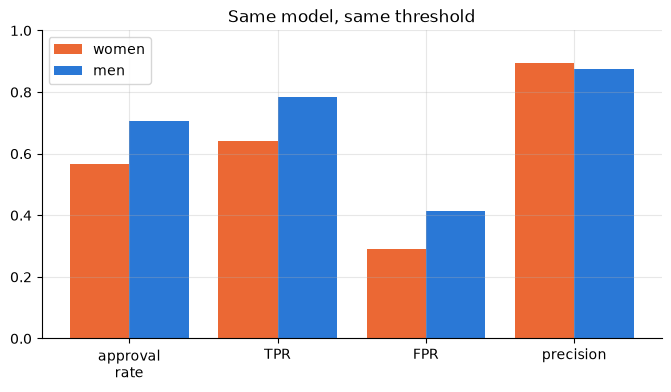

In [13]:
cols = ["approval rate", "TPR (good payers approved)", "FPR (defaulters approved)", "precision (approved who repay)"]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cols))
ax.bar(x - 0.2, base.loc["F", cols], width=0.4, color=ORANGE, label="women")
ax.bar(x + 0.2, base.loc["M", cols], width=0.4, color=BLUE, label="men")
ax.set_xticks(x, ["approval\nrate", "TPR", "FPR", "precision"])
ax.set_ylim(0, 1); ax.set_title("Same model, same threshold"); ax.legend()
plt.show()

In [15]:
gap = base.loc["M", "TPR (good payers approved)"] - base.loc["F", "TPR (good payers approved)"]
print(f"DI ratio {di_ratio(base):.2f};  TPR gap {gap:.1%} points")
print(base[["actual default rate", "mean predicted PD"]].round(3))

DI ratio 0.80;  TPR gap 14.3% points
   actual default rate  mean predicted PD
F                0.208              0.239
M                0.212              0.194


### Some Observations

1. Approval: about 57% of women vs 71% of men. The ratio is about 0.80: right at the line (Simulations are so nice!). It "passes" the rule of thumb, which is exactly why one metric is not enough.

2. TPR: about 64% for women vs 78% for men. Of the women who WOULD have repaid, about 36% are refused, against 22% of men. A good female payer is refused far more often: about a 14-point gap in equal opportunity.

## C2. Does a score mean the same thing for women and men?

**Calibration** by group: among applicants with similar predicted risk, compare the share who actually defaulted.

In [14]:
bins = [0, 0.10, 0.20, 0.30, 0.45, 1]
calib = (test.assign(risk_band=pd.cut(test["p_default"], bins))
             .pivot_table(index="risk_band", columns="gender", values="default",
                          aggfunc=["mean", "size"], observed=False))
calib.columns = [f"{'actual default' if a == 'mean' else 'n'} {g}" for a, g in calib.columns]
calib.round(3)

,actual default F,actual default M,n F,n M
risk_band,,,,
"(0.0, 0.1]",0.052,0.059,192,374
"(0.1, 0.2]",0.118,0.162,346,457
"(0.2, 0.3]",0.194,0.283,248,230
"(0.3, 0.45]",0.335,0.368,191,171
"(0.45, 1.0]",0.556,0.716,117,74


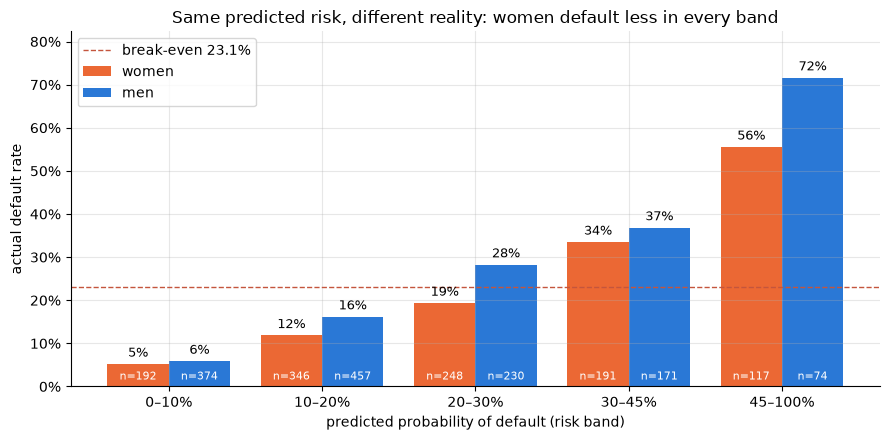

In [16]:
labels = ["0–10%", "10–20%", "20–30%", "30–45%", "45–100%"]
x = np.arange(len(calib))

fig, ax = plt.subplots(figsize=(9, 4.5))
for offset, g, color, name in [(-0.2, "F", ORANGE, "women"), (0.2, "M", BLUE, "men")]:
    bars = ax.bar(x + offset, calib[f"actual default {g}"], width=0.4, color=color, label=name)
    for b, v, n in zip(bars, calib[f"actual default {g}"], calib[f"n {g}"]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
        ax.text(b.get_x() + b.get_width() / 2, 0.01, f"n={n}", ha="center", va="bottom", fontsize=8, color="white")
ax.axhline(BREAK_EVEN, color=RED, ls="--", lw=1, label="break-even 23.1%")
ax.set_xticks(x, labels)
ax.set_xlabel("predicted probability of default (risk band)")
ax.set_ylabel("actual default rate")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_ylim(0, calib.filter(like="actual").max().max() * 1.15)
ax.set_title("Same predicted risk, different reality: women default less in every band")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Some Observations Here

Women and men actually default at almost the same rate in the test set (about 21%), but the model predicts a HIGHER risk for women (about 24% vs 19%). In the calibration table, women default less than men in the same risk band. The model overestimates women's risk.

# Part D — The proxy test

The model never saw `gender`. Can the **other** features tell women from men?

We train a second model that tries to predict `gender` from the credit model's features. If its AUC is well above 0.5, the information is still in the data. These tests will become routine with new regulations coming from EU ,so better be prepared.

In [17]:
proxy = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
proxy.fit(features(train), train["gender"] == "F")
proxy_auc = roc_auc_score(test["gender"] == "F", proxy.predict_proba(features(test))[:, 1])
print(f"AUC of predicting 'female' from the credit features: {proxy_auc:.3f}")

# Standardised coefficients: how strongly each feature points to "female" (+) or "male" (-)
proxy_coef = pd.Series(proxy[-1].coef_[0], index=features(train).columns).sort_values(key=abs, ascending=False)
proxy_coef.round(2)

AUC of predicting 'female' from the credit features: 0.839


career_gap_months           1.10
log_income                 -0.89
part_time                   0.25
employment_self-employed   -0.17
age                         0.16
employment_public           0.13
region_Rural               -0.12
credit_history_months      -0.04
region_Tirana               0.04
late_payments_12m          -0.04
debt_to_income             -0.04
log_loan                    0.02
dtype: float64

### Comments

1. About 0.84: the features separate women from men very well. The information is there.

2. Columns, especially career gaps, income and part-time work, carry most of the gender information, so the model can treat women differently without ever seeing the word "female". Only an audit of the outcomes by group, like Part C, can show whether it does.

3. The three strongest predictors: career_gap_months (strongest), log_income, part_time (then age). Income is a legitimate credit factor: lenders must check affordability. A career gap in itself is not obviously a sign of bad repayment; it is mostly parental leave or illness.

# Part E — Moving the threshold: what fairness costs

## E1. One threshold for everyone

We try every common threshold from 10% to 40% and record profit, the DI ratio and the TPR gap. This is a bit advanced, but spend some time trying to understand it:

In Part B we used a single cut-off, the break-even probability of 23.1%. Here we try every threshold from 10% to 40% in steps of one percentage point, and the same threshold applies to everyone. For each threshold, the sweep() function approves every applicant whose predicted probability of default is below it. It then runs the Part C audit on those decisions and records five numbers: 

1. total profit on the test set (+€300 per repaid loan, −€1,000 per default)
2. The approval rate for women (F)
3. Approval rate for men (M)
4. The disparate impact ratio
5. The TPR gap (men’s TPR minus women’s TPR).
  

The table shows every third threshold to keep it short; the full results are stored in grid. The left chart shows how profit changes as the threshold moves. The right chart shows the two fairness measures, both turned so that 1 means “equal”: the DI ratio, and 1 minus the TPR gap. The red dashed line marks the break-even threshold, and the dotted line marks the four-fifths (0.8) rule of thumb. 

Comparing the two charts shows what each step towards fairness costs in profit when one threshold applies to everyone.

In [18]:
def sweep(df, thresholds):
    rows = []
    for t in thresholds:
        a = df["p_default"] < t
        tab = audit(df, a)
        rows.append({"threshold": t, "profit €": profit(df, a), "approval F": tab.loc["F", "approval rate"],
                     "approval M": tab.loc["M", "approval rate"], "DI ratio": di_ratio(tab),
                     "TPR gap (M - F)": tab.loc["M", "TPR (good payers approved)"] - tab.loc["F", "TPR (good payers approved)"]})
    return pd.DataFrame(rows).set_index("threshold")

grid = sweep(test, np.round(np.arange(0.10, 0.401, 0.01), 2))
grid.iloc[::3].round(3)

,profit €,approval F,approval M,DI ratio,TPR gap (M - F)
threshold,,,,,
0.10,128200,0.176,0.286,0.613,0.132
0.13,170400,0.276,0.413,0.669,0.156
0.16,208700,0.384,0.533,0.720,0.157
0.19,222100,0.465,0.612,0.760,0.153
0.22,224700,0.544,0.685,0.794,0.146
0.25,229200,0.606,0.744,0.814,0.137
0.28,217700,0.676,0.789,0.858,0.102
0.31,210300,0.735,0.827,0.889,0.079
0.34,203200,0.782,0.855,0.915,0.055


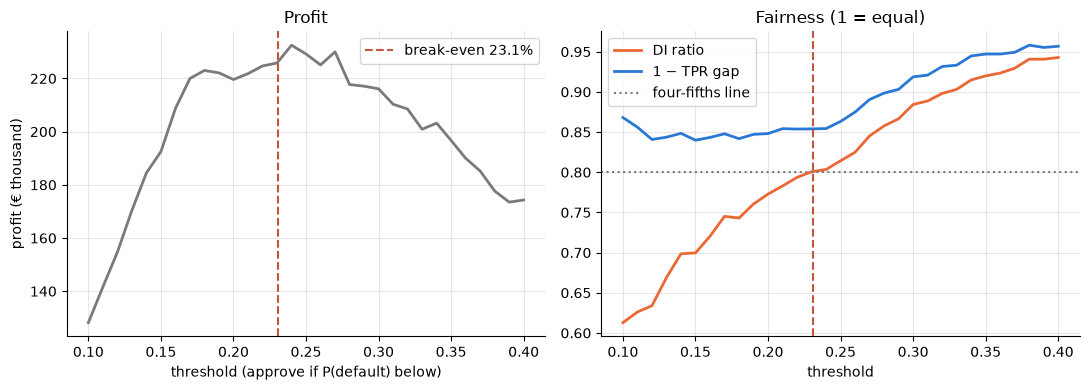

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(grid.index, grid["profit €"] / 1000, color=GREY, lw=2)
ax1.axvline(BREAK_EVEN, color=RED, ls="--", label="break-even 23.1%")
ax1.set_xlabel("threshold (approve if P(default) below)"); ax1.set_ylabel("profit (€ thousand)")
ax1.set_title("Profit"); ax1.legend()
ax2.plot(grid.index, grid["DI ratio"], color=ORANGE, lw=2, label="DI ratio")
ax2.plot(grid.index, 1 - grid["TPR gap (M - F)"], color=BLUE, lw=2, label="1 − TPR gap")
ax2.axhline(0.8, color=GREY, ls=":", label="four-fifths line")
ax2.axvline(BREAK_EVEN, color=RED, ls="--")
ax2.set_xlabel("threshold"); ax2.set_title("Fairness (1 = equal)"); ax2.legend()
plt.tight_layout(); plt.show()

**Left Chart**: Profit climbs steeply from 10% to about 17%. At a very strict threshold, almost every extra applicant approved is a good payer, so each step adds a lot: profit goes from about €128k at 10% to €220k at 17%. Between about 17% and 27% the curve is a broad, flat top, between €220k and €233k. Beyond about 28% it falls steadily, to €174k at 40%: the extra applicants now include more and more defaulters, and each default wipes out the profit of more than three good loans.

Any threshold from about 18% to 27% is within roughly €10k (about 5%) of the best result. The decision is robust, and there is some room to choose a threshold for reasons other than profit, such as fairness, at little cost.

**Right Chart**: 1 − (TPR_men − TPR_women) where TPR (true-positive rate) is the share of good payers in a group who are approved. At the break-even threshold, men’s TPR is 0.784 and women’s is 0.641. The gap is 0.784 − 0.641 = 0.143, so the line sits at 1 − 0.143 ≈ 0.86. It equals 1 when good payers in both groups have the same chance of approval, and it falls as the gap widens. A rising DI ratio here does not mean the model is getting fairer; it means the bank is approving almost everyone. Across the whole profitable range, moving the threshold does nothing for equal opportunity: a woman who would repay is always about 15 points less likely to be approved than a man who would repay. The gap shrinks only beyond about 25%, falling to about 10 points at 28% and about 5 points from 34% upwards. By then most good payers in both groups are approved, so there is little room left for a gap.

## E2. A separate threshold for women

Keep men at the break-even threshold and **raise the threshold for women only**, so more women are approved.

> ⚠️ **Legal warning (lecture slide 13).** Using a different rule because of a person's sex is **direct discrimination** under EU law, which is very hard to justify (see *Test-Achats*, CJEU 2011). We compute it to see the trade-off, **not** because the bank could simply do it.

In [21]:
def two_thresholds(df, t_f, t_m=BREAK_EVEN):
    t = np.where(df["gender"] == "F", t_f, t_m)
    return pd.Series(df["p_default"].values < t, index=df.index)

rows = []
for t_f in [0.231, 0.25, 0.27, 0.29, 0.31, 0.33]:
    a = two_thresholds(test, t_f)
    tab = audit(test, a)
    rows.append({"threshold women": t_f, "approval F": tab.loc["F", "approval rate"],
                 "DI ratio": di_ratio(tab), "TPR F": tab.loc["F", "TPR (good payers approved)"],
                 "TPR M": tab.loc["M", "TPR (good payers approved)"],
                 "defaults approved F": int((a & (test["gender"] == "F") & (test["default"] == 1)).sum()),
                 "profit €": profit(test, a)})
separate = pd.DataFrame(rows).set_index("threshold women")
separate.round(3)

,approval F,DI ratio,TPR F,TPR M,defaults approved F,profit €
threshold women,,,,,,
0.231,0.568,0.804,0.641,0.784,66,227600
0.250,0.606,0.858,0.682,0.784,72,232400
0.270,0.652,0.923,0.732,0.784,79,238300
0.290,0.695,0.984,0.769,0.784,94,232900
0.310,0.735,0.961,0.807,0.784,105,231800
0.330,0.767,0.921,0.836,0.784,115,229300


In [ ]:
# Exercise 5
# 1. With ONE common threshold, can you reach a DI ratio of 0.9 or close the TPR gap?
#    What happens to profit?
# 2. With separate thresholds: which threshold for women roughly equalises TPR?
#    What does it cost compared with the break-even policy (in € and in %)?
# 3. Surprise question: in E2, does profit go DOWN as we approve more women? Why or why not?
#    (Hint: Part C, exercise 3, question 3.)

# Part F — Remove the strongest proxy

The obvious "fix": drop `career_gap_months`, the strongest proxy from Part D, and refit. Then drop `part_time` too.
The function below refits the model with any set of features and returns the key audit numbers.

In [ ]:
def refit_and_audit(drop=(), add_gender=False, t=BREAK_EVEN):
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(features(train, drop, add_gender), train["default"])
    d = test.copy()
    d["p_default"] = m.predict_proba(features(d, drop, add_gender))[:, 1]
    a = d["p_default"] < t
    tab = audit(d, a)
    return {"AUC": roc_auc_score(d["default"], d["p_default"]), "profit €": profit(d, a),
            "approval F": tab.loc["F", "approval rate"], "approval M": tab.loc["M", "approval rate"],
            "DI ratio": di_ratio(tab),
            "TPR F": tab.loc["F", "TPR (good payers approved)"], "TPR M": tab.loc["M", "TPR (good payers approved)"],
            "pred. PD F": tab.loc["F", "mean predicted PD"], "actual F": tab.loc["F", "actual default rate"]}

versions = pd.DataFrame({
    "all features": refit_and_audit(),
    "drop career gap": refit_and_audit(drop=["career_gap_months"]),
    "drop career gap + part time": refit_and_audit(drop=["career_gap_months", "part_time"]),
}).T
versions.round(3)

In [ ]:
# What drives the credit model? Standardised coefficients (+ = more risk)
credit_coef = pd.Series(model[-1].coef_[0], index=features(train).columns).sort_values(key=abs, ascending=False)
credit_coef.round(2)

In [ ]:
# Exercise 6
# 1. Did dropping the strongest proxy close the gap? Look at the credit model's coefficients:
#    which feature really drives the difference between women and men?
# 2. Could DritaKredit simply drop income too? Give a legal and a business reason.
# 3. Optional: run refit_and_audit(add_gender=True). What happens to the gap and to profit?
#    Why is this the fix the law forbids, even though it makes the model MORE accurate for women?
# 4. Name two things DritaKredit could do legally to reduce the gap.

### Optional (fast groups): audit by age

Applicants under 30 have shorter credit histories. Make an `age_group` column ("under 30" / "30 and over") and run `audit(test, test["approved"], group="age_group")`. Is the model fair by age? Age is also a protected ground under EU equality law.

In [ ]:
# Optional exercise — your code here

# Part G — Classify ten use cases by AI Act risk tier (seminar part 2)

In pairs. For each use case choose **prohibited**, **high**, **transparency** or **minimal**, and give the reason (the article or Annex III point). Lecture slides 23–27. This is midterm practice: one mark for the tier, one for the reason.

| # | Use case |
|---|---|
| 1 | A Tirana bank's model scores personal-loan applicants from Italy |
| 2 | A card-payment model flags transactions as possible fraud |
| 3 | A telco's website chatbot answers billing questions |
| 4 | Software rates call-centre agents' mood from their voices |
| 5 | A supermarket chain ranks job applicants' CVs |
| 6 | A churn model picks who gets a retention discount (week 3) |
| 7 | A realistic AI video of the CEO is used in a public ad campaign |
| 8 | A city scores residents' "civic behaviour" to rank housing support |
| 9 | An insurer prices life and health policies with a model |
| 10 | A university uses AI proctoring to flag cheating in online exams |

In [ ]:
TIERS = {"prohibited", "high", "transparency", "minimal"}

my_answers = {   # replace "?" with a tier, and write the reason
    1:  ("?", ""),
    2:  ("?", ""),
    3:  ("?", ""),
    4:  ("?", ""),
    5:  ("?", ""),
    6:  ("?", ""),
    7:  ("?", ""),
    8:  ("?", ""),
    9:  ("?", ""),
    10: ("?", ""),
}

answers = pd.DataFrame(my_answers, index=["tier", "reason"]).T
print("Not a valid tier yet:", [k for k, (t, _) in my_answers.items() if t not in TIERS])
answers["tier"].value_counts()

# Part H — Memo to the credit committee (seminar deliverable)

Write about **150 words** in the cell below (or in a Word file). Use your numbers.
1. **Recommendation:** launch the model as it is, change it, or delay? Which threshold?
2. **Fairness:** which metric you would manage, and why that one (lecture slide 14).
3. **Price:** what closing the gap would cost or gain, in euros.
4. **One legal point** under the AI Act or GDPR that the committee must know.

*Your memo here.*

---
## Discussion (5 minutes)
- The vendor says: *"Our model is fair: it doesn't use gender, and it passes the four-fifths rule."* What would you answer, using today's numbers?
- In Part E, approving more women did not cost money; it even raised profit. Why might the bank still not have noticed the problem without an audit?
- Your project: which group could be harmed most by your model's errors, and which metric will you report?

---
# Exit ticket (on paper)

**Q1.** Group A: 400 applicants, 300 good payers; the model approves 240 good payers and 40 defaulters. Group B: 400 applicants, 300 good payers; it approves 180 good payers and 20 defaulters. Compute each group's approval rate and TPR, and the disparate impact ratio.

**Q2.** "We removed gender, so the model is fair." Give two reasons why that is not enough.

**Q3.** Classify by AI Act tier: (a) a chatbot answering questions about insurance policies; (b) a model setting health-insurance premiums; (c) software rating employees' emotions during video calls.